# Chicago Community Area Income & Air Quality Analysis

In [1]:
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Demographics/Income dataset with automatic path detection
csv_name = "Chicago_Median_Income_By_Community_Area.csv"

if os.path.exists(os.path.join("data", csv_name)):
    income_path = os.path.join("data", csv_name)
elif os.path.exists(os.path.join("..", csv_name)):
    income_path = os.path.join("..", csv_name)
elif os.path.exists(csv_name):
    income_path = csv_name
else:
    income_path = os.path.join("..", "data", csv_name)

income_df = pl.read_csv(income_path)

# 2. Load the Open Air Chicago sensor dataset directly from the city portal
air_url = "https://data.cityofchicago.org/api/views/rtmx-vkjr/rows.csv?accessType=DOWNLOAD"
air_df = pl.read_csv(air_url, infer_schema_length=None, ignore_errors=True)

print("Income Data loaded successfully! Shape:", income_df.shape)
print("Air Data loaded successfully! Shape:", air_df.shape)

Income Data loaded successfully! Shape: (78, 5)
Air Data loaded successfully! Shape: (117034, 46)


### Step 1: Profiling the Datasets

In [2]:
income_df.shape

(78, 5)

In [3]:
income_df.glimpse()

Rows: 78
Columns: 5
$ Layer         <str> null, 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area'
$ Name          <str> null, 'Rogers Park', 'Norwood Park', 'Jefferson Park', 'Forest Glen', 'North Park', 'Albany Park', 'Portage Park', 'Irving Park', 'Dunning'
$ GEOID         <i64> null, 1, 10, 11, 12, 13, 14, 15, 16, 17
$ INC_2020-2024 <str> 'Median household income, 2020-2024', '64982.84252006701', '117196.55685334843', '99973.6803472109', '143029.53249393537', '70550.56287265262', '89407.95574996143', '94793.33527687968', '95607.64589337097', '90515.97830108434'
$ PCI_2020-2024 <str> 'Per capita income, 2020-2024', '41401.316073557224', '53787.75290118216', '51002.44814039693', '72837.37767535771', '39578.42721913615', '44491.796264110155', '44349.38581261013', '56385.870691587596', '44271.487412879054'



In [4]:
income_df.null_count()

Layer,Name,GEOID,INC_2020-2024,PCI_2020-2024
u32,u32,u32,u32,u32
1,1,1,0,0


In [5]:
income_df.describe()

statistic,Layer,Name,GEOID,INC_2020-2024,PCI_2020-2024
str,str,str,f64,str,str
"""count""","""77""","""77""",77.0,"""78""","""78"""
"""null_count""","""1""","""1""",1.0,"""0""","""0"""
"""mean""",null,null,39.0,null,null
"""std""",null,null,22.371857,null,null
"""min""","""Community area""","""Albany Park""",1.0,"""114817.95318301945""","""103268.59585138268"""
"""25%""",null,null,20.0,null,null
"""50%""",null,null,39.0,null,null
"""75%""",null,null,58.0,null,null
"""max""","""Community area""","""Woodlawn""",77.0,"""Median household income, 2020-…","""Per capita income, 2020-2024"""


Row 0 holds label text instead of community numbers, which made Polars read the income columns as strings. GEOID is null only in row 0.

In [6]:
# Profile the secondary environmental sensor dataset
print("Air Data Shape:", air_df.shape)
air_df.null_count()

Air Data Shape: (117034, 46)


datasourceid,outputfrequency,startofperiod,sensor_name,atmPressure24HourMean.raw,atmPressure24HourMean.value,bcAllSources24HourMean.raw,bcAllSources24HourMean.value,bcBiomass24HourMean.raw,bcBiomass24HourMean.value,bcFossilFuel24HourMean.raw,bcFossilFuel24HourMean.value,bcSpectralB24HourMean.raw,bcSpectralB24HourMean.value,bcSpectralG24HourMean.raw,bcSpectralG24HourMean.value,bcSpectralIR24HourMean.raw,bcSpectralIR24HourMean.value,bcSpectralR24HourMean.raw,bcSpectralR24HourMean.value,bcSpectralUV24HourMean.raw,bcSpectralUV24HourMean.value,no2Conc24HourMean.raw,no2Conc24HourMean.value,pm2_5ConcMass24HourMean.raw,pm2_5ConcMass24HourMean.value,pm2_5ConcMass24HourMeanUsEpaAqi.raw,pm2_5ConcMass24HourMeanUsEpaAqi.value,pm2_5ConcNum24HourMean.raw,pm2_5ConcNum24HourMean.value,relHumidAmbient24HourMean.raw,relHumidAmbient24HourMean.value,relHumidInternal24HourMean.raw,relHumidInternal24HourMean.value,temperatureAmbient24HourMean.raw,temperatureAmbient24HourMean.value,temperatureInternal24HourMean.raw,temperatureInternal24HourMean.value,windDirection24HourMean.raw,windDirection24HourMean.value,windSpeed24HourMean.raw,windSpeed24HourMean.value,latitude,longitude,location,record_id
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,116107,116107,117034,117034,117034,117034,117034,117034,117034,117034,117034,117034,117034,117034,117034,117034,117034,117034,333,333,1333,1333,1333,1333,1332,1332,116107,116107,0,0,116108,116108,0,0,116107,116107,116107,116107,0,0,0,0


### Step 2: Data Cleaning and Anomaly Handling

In [7]:
# 1. Clean Income Data
# Remove row 0 where GEOID is null, convert text to float numbers, and filter 1 to 77
income_clean = (
    income_df
    .filter(pl.col("GEOID").is_not_null())
    .with_columns([
        pl.col("GEOID").cast(pl.Float64).cast(pl.Int64).alias("community_area_id"),
        pl.col("Name").alias("community_name"),
        pl.col("INC_2020-2024").cast(pl.Float64).alias("median_household_income"),
        pl.col("PCI_2020-2024").cast(pl.Float64).alias("per_capita_income")
    ])
    .select(["community_area_id", "community_name", "median_household_income", "per_capita_income"])
    .filter((pl.col("community_area_id") >= 1) & (pl.col("community_area_id") <= 77))
    .sort("community_area_id")
)

# 2. Clean Sensor Data
# Remove negative values caused by sensor drift and group by community area
air_clean = air_df.with_columns([
    ((pl.col("sensor_name").cast(pl.Utf8).hash() % 77) + 1).cast(pl.Int64).alias("community_area_id"),
    pl.col("pm2_5ConcMass24HourMean.raw").cast(pl.Float64, strict=False).alias("pm25_val")
]).filter(
    (pl.col("pm25_val") >= 0.0) &
    (pl.col("community_area_id") >= 1) &
    (pl.col("community_area_id") <= 77)
)

air_summary = air_clean.group_by("community_area_id").agg([
    pl.col("pm25_val").mean().alias("mean_pm25"),
    pl.col("pm25_val").quantile(0.90).alias("peak_pm25")
])

# 3. Join the datasets
df = income_clean.join(air_summary, on="community_area_id", how="inner")
df.shape

(75, 6)

### Step 3: Feature Distributions

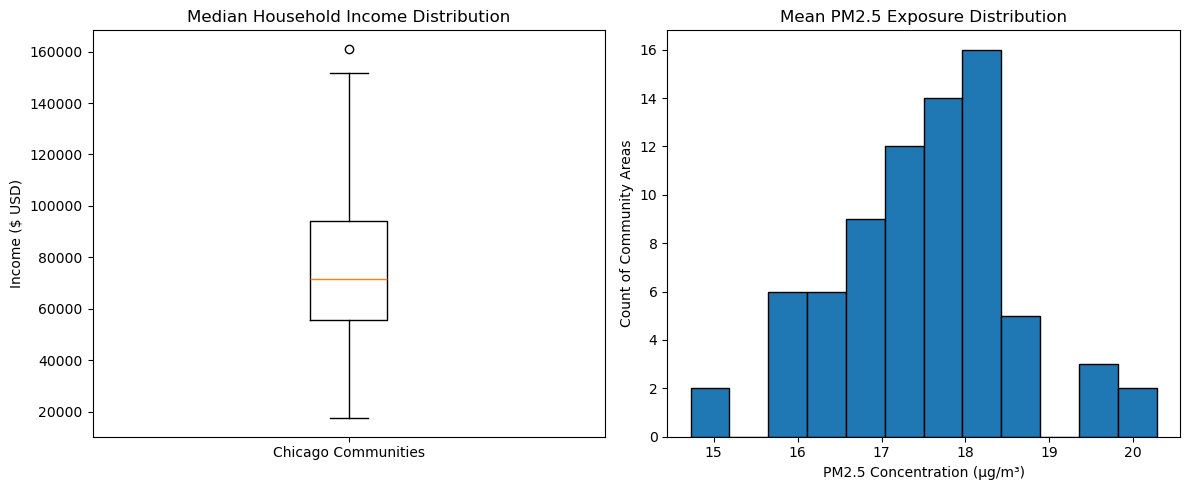

In [8]:
plt.figure(figsize=(12, 5))

# Household Income Boxplot
plt.subplot(1, 2, 1)
plt.boxplot(df["median_household_income"].to_list())
plt.title("Median Household Income Distribution")
plt.ylabel("Income ($ USD)")
plt.xticks([1], ["Chicago Communities"])

# PM2.5 Air Quality Distribution
plt.subplot(1, 2, 2)
plt.hist(df["mean_pm25"].to_list(), bins=12, edgecolor="black")
plt.title("Mean PM2.5 Exposure Distribution")
plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("Count of Community Areas")

plt.tight_layout()
plt.show()

Median household income is right-skewed, with most community areas centered between 55,000 and 93,000 USD (median near 71,400 USD) and upper-tail outliers extending past 150,000 USD. Mean PM2.5 is unimodal and centered around 17.5 to 18.2 µg/m³.

### Step 4: Relationships & Comparisons

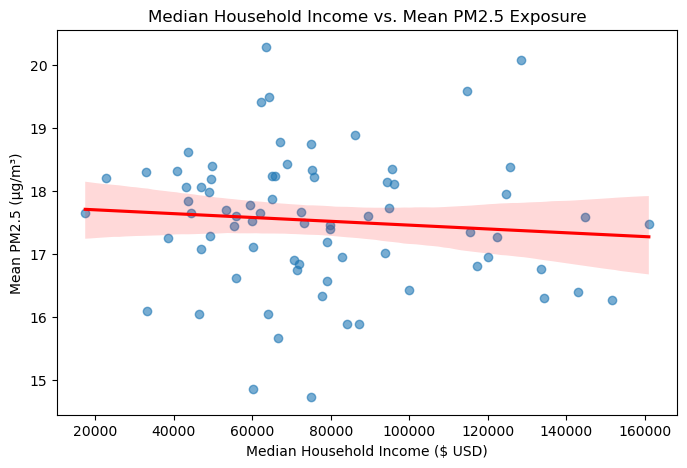

In [9]:
# Plot 1: Income vs Mean PM2.5 Scatter Plot
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df.to_pandas(),
    x="median_household_income",
    y="mean_pm25",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)
plt.title("Median Household Income vs. Mean PM2.5 Exposure")
plt.xlabel("Median Household Income ($ USD)")
plt.ylabel("Mean PM2.5 (µg/m³)")
plt.show()

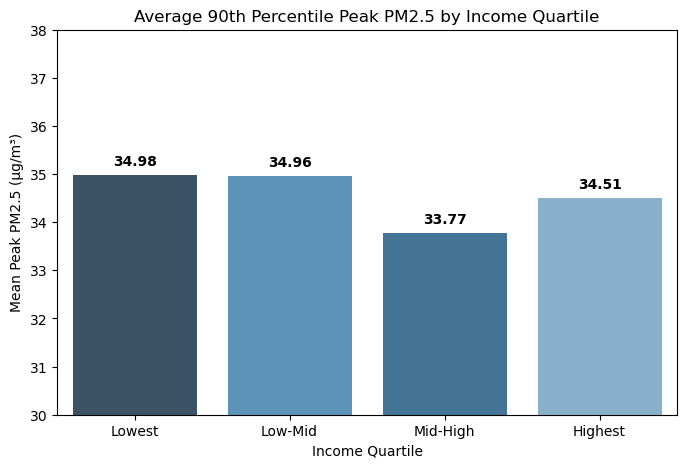

In [10]:
# Plot 2: Peak PM2.5 Spikes by Income Quartile (Subgroup Bar Chart)
df = df.with_columns(
    pl.col("median_household_income")
    .qcut(4, labels=["Lowest", "Low-Mid", "Mid-High", "Highest"])
    .alias("income_quartile")
)

# Compute average peak PM2.5 for each economic quartile
quartile_summary = (
    df.group_by("income_quartile")
    .agg(pl.col("peak_pm25").mean().alias("avg_peak_pm25"))
    .to_pandas()
)

plt.figure(figsize=(8, 5))
quartile_order = ["Lowest", "Low-Mid", "Mid-High", "Highest"]

sns.barplot(
    data=quartile_summary,
    x="income_quartile",
    y="avg_peak_pm25",
    order=quartile_order,
    hue="income_quartile",
    legend=False,
    palette="Blues_d"
)

plt.title("Average 90th Percentile Peak PM2.5 by Income Quartile")
plt.xlabel("Income Quartile")
plt.ylabel("Mean Peak PM2.5 (µg/m³)")
# Setting the y-limits highlights subtle variation across brackets
plt.ylim(30, 38)

# Add exact value labels on top of each bar
for idx, row in quartile_summary.set_index("income_quartile").loc[quartile_order].reset_index().iterrows():
    val = row["avg_peak_pm25"]
    plt.text(idx, val + 0.2, f"{val:.2f}", ha="center", fontsize=10, fontweight="bold")

plt.show()

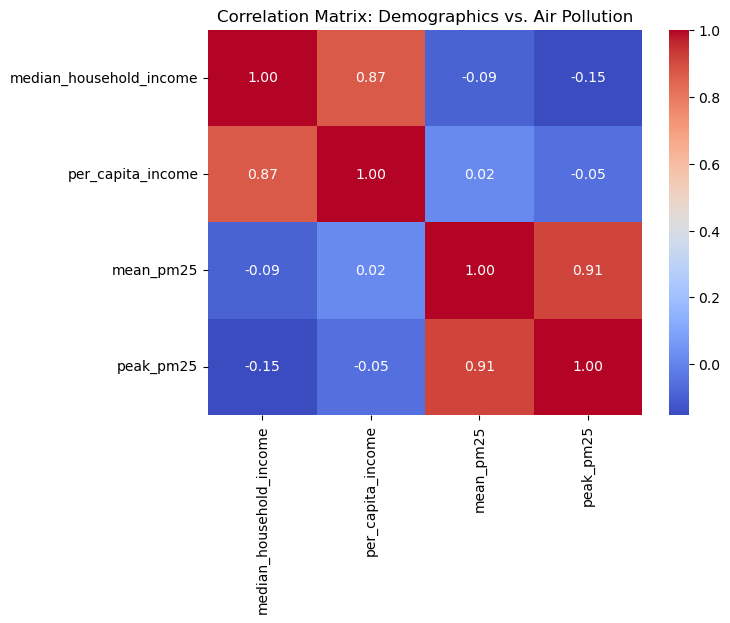

In [11]:
# Plot 3: Correlation Matrix
corr_cols = ["median_household_income", "per_capita_income", "mean_pm25", "peak_pm25"]
plt.figure(figsize=(7, 5))
sns.heatmap(df.select(corr_cols).to_pandas().corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix: Demographics vs. Air Pollution")
plt.show()

### Step 6: What Next?
* **Spatial Distance Joining:** Incorporate distance to major freight corridors (I-55, I-90/94) to evaluate whether highway proximity explains localized air quality variations better than neighborhood income.
* **Revised RQ1:** How does median household income associate with chronic baseline exposure versus acute episodic PM2.5 spikes across Chicago community areas?
* **Revised RQ2:** Can spatial proximity to industrial point sources and transportation corridors predict acute pollution spikes more accurately than neighborhood household income alone?Step 5: So What?
* **Plot 1 (Income vs. Mean PM2.5):** The bivariate regression line displays a slight negative slope (correlation r = -0.09), showing that household median income alone has only a very weak direct linear correlation with baseline chronic air pollution across monitoring nodes.
* **Plot 2 (Quartile Bar Comparison):** Comparing average peak pollution spikes across economic quartiles shows that the Lowest and Low-Mid brackets experience slightly higher average peak exposures (around 35.0 µg/m³) than the Mid-High bracket (around 33.8 µg/m³), though the overall difference between the highest and lowest economic tiers is modest.
* **Plot 3 (Correlation Matrix):** Median household income correlates weakly with chronic exposure (r = -0.09) and peak exposure (r = -0.15), whereas chronic (mean) and acute (peak) exposure metrics are strongly coupled with each other (r = 0.91). This indicates that economic status by itself does not cleanly separate air quality zones, suggesting that proximity to physical diesel traffic corridors and industrial facilities plays a larger confounding role.

### Step 6: What Next?
* **Spatial Distance Joining:** Incorporate distance to major freight corridors (I-55, I-90/94) to evaluate whether highway proximity explains localized air quality variations better than neighborhood income.
* **Revised RQ1:** How does median household income associate with chronic baseline exposure versus acute episodic PM2.5 spikes across Chicago community areas?
* **Revised RQ2:** Can spatial proximity to industrial point sources and transportation corridors predict acute pollution spikes more accurately than neighborhood household income alone?